# Análise Exploratória de Dados (EDA) e Higienização - Credit Scoring

Esse notebook realiza a exploração aprofundada da base de dados do *Give Me Same Credit*, com foco em:
1. Conexão com o banco SQLite e carregamento dos dados.
2. Auditoria de valores ausentes (*missing values*).
3. Identificação e tratamentos de outliers/erros de coleta.
4. Análise da distribuição da variável alvo (`SeriousDlqin2yrs`).

### Imports e Conexão com o SQLite

In [4]:
# 1. Importação das bibliotecas essenciais para EDA e manipulação de dados
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Configuração para exibir todas as colunas e gráficos no Jupyter
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

print("Bibliotecas importadas com sucesso!\n")

# 3. Conexão com o banco SQLite criado na ingestão
caminho_db = "../data/credit_scoring.db"
conexao = sqlite3.connect(caminho_db)

# 4. Carregando os dados de treino para um DataFrame do Pandas
df = pd.read_sql("SELECT * FROM credito_treino", conexao)
conexao.close()

print(f"Dados carregados do banco SQLite! \nDimensões do DataFrame: {df.shape[0]} linhas e {df.shape[1]} colunas.")

Bibliotecas importadas com sucesso!

Dados carregados do banco SQLite! 
Dimensões do DataFrame: 150000 linhas e 11 colunas.


### Etapa 1 - Auditoria Inicial: Tipos de Dados e Valores Ausentes (*Missing Values*)

Nessa etapa, vamos inspecionar o esquema do DataFrame para verificar os tipos de dados de cada coluna e mapear a presença de valores nulos. 

Informações gerais do DataFrame:
<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 n

None



Auditoria de Valores Ausentes:


,Valores Nulos,Porcentagem (%)
MonthlyIncome,29731,19.82
NumberOfDependents,3924,2.62


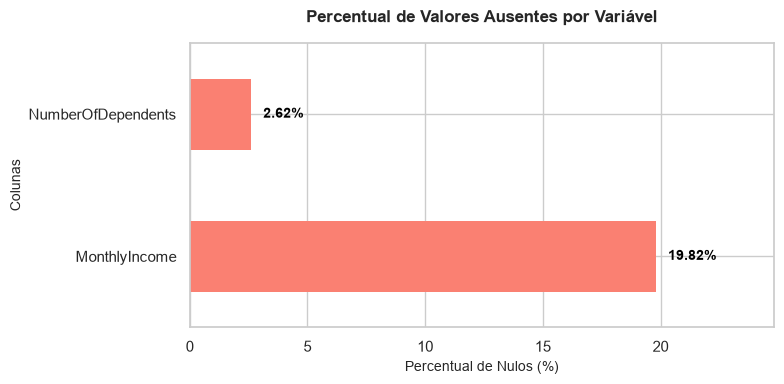

In [12]:
## Análise de Nulos e Tipos

# 1. Verificando informações gerais do DataFrame e tipos de dados
print("Informações gerais do DataFrame:")
display(df.info())

print("\n" + "="*50 + "\n")

# 2. Analisando os valores nulos absolutos e percentuais 
nulos = df.isnull().sum()
percentual_nulos = (df.isnull().mean() * 100).round(2)

df_nulos = pd.DataFrame({
    'Valores Nulos': nulos,
    'Porcentagem (%)': percentual_nulos
})

print("Auditoria de Valores Ausentes:")
display(df_nulos[df_nulos['Valores Nulos'] > 0])

# 3. Visualização Gráfica dos Valores Ausentes 
plt.figure(figsize=(8, 4))
nulos_filtrados = percentual_nulos[percentual_nulos > 0]

ax = nulos_filtrados.plot(kind='barh', color='salmon', edgecolor='none')
plt.title('Percentual de Valores Ausentes por Variável', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Percentual de Nulos (%)', fontsize=10)
plt.ylabel('Colunas', fontsize=10)

# Adicionando os valores nas barras para leitura rápida
for p in ax.patches:
    width = p.get_width() # type: ignore
    ax.annotate(f'{width:.2f}%',
                (width + 0.5, p.get_y() + p.get_height() / 2.), # type: ignore
                ha='left', va='center',
                fontsize=10, color='black', fontweight='bold')

plt.xlim(0, max(nulos_filtrados.values) + 5)
plt.tight_layout()
plt.show()

#### Conclusão Auditoria Inicial (Tipos de Dados e Valores Ausentes):
- **`MonthlyIncome` (Renda Mensal):** Apresenta ~19,82% de valores ausentes (29.731 linhas). Em termos de risco de crédito, a renda é uma variável crítica. Precisaremos definir uma estratégia de imputação (como a mediana agrupada por faixa de idade ou uso de modelos preditivos) para não inviabilizar o modelo. 
- **`NumberOfDependents` (Número de Dependentes):** Possui ~2,62% de valores ausentes (3.924 linhas). Nesse caso, como o volume é pequeno frente ao total de 150.000 linhas, a imputação por valor central (moda ou mediana) ou remoção pontual é viável. 

### Etapa 2: Início da Investigação Estatística e Outliers
#### Estatística Descritiva e Identificação de Anomalias (*outliers*)

Nessa etapa, vamos analisar as estatísticas descritivas do DataFrame para identificar valores que fogem da realidade (como idades inválidas) e os códigos de artefato do dataset (como 96 e 98 nas colunas atraso).

In [14]:
# 1. Estatísticas descritivas para inspeção (mínimo, máximo, média e quartis)
print("Estatísticas Descritivas Básicas:")
display(df.describe().T)

# 2. Verificando valores únicos nas colunas de atraso para identificar códigos de erro/artefatos
print("\n Investigando valores únicos nas colunas de histórico de atraso:")
cols_atraso = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate',
    'NumberOfTime60-89DaysPastDueNotWorse'
]

for col in cols_atraso:
    print(f"\nValores únicos em {col}:")
    print(sorted(df[col].unique()))

Estatísticas Descritivas Básicas:


,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.240387,4.155179,0.0,0.000000,0.000000,0.000000,98.0



 Investigando valores únicos nas colunas de histórico de atraso:

Valores únicos em NumberOfTime30-59DaysPastDueNotWorse:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(96), np.int64(98)]

Valores únicos em NumberOfTimes90DaysLate:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(17), np.int64(96), np.int64(98)]

Valores únicos em NumberOfTime60-89DaysPastDueNotWorse:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(11), np.int64(96), np.int64(98)]


#### Conclusão Estatística Descritiva e Identificação de Outliers:
1. **Idade Mínima (`age`):** Encontramos `min = 0`, o que biologicamente é impossível para tomadores de crédito. Precisamos filtrar ou tratar essas linhas.

2. **Os Valores Fantasmas (`96` e `98`) nas Colunas de Atraso:** Nas colunas `NumberOfTime30-59DaysPartDueNotWorse`, `NumberOfTimes90DaysLate` e `NumberOfTime60-89DaysPastDueNotWorse`, os valores únicos revelam a presença de `96` e `98`. Na documentação desse dataset, esses números não representam dias de atraso reais, mas sim **códigos de sistema / valores especiais** (geralmente indicando ausência de dados, clientes inativos ou casos omissos). Menter esses valores como números faria o algoritmo achar que um cliente atrasou 98 vezes, distorcendo totalmente o modelo de risco. Precisamos tratá-los (convertendo para nulos ou imputando adequadamente).

3. **Utilização de Crédito e Dívida (`RevolvingUtilizationOfUnsecuredLines` e `DebtRatio`):** Apresentam valores máximos absurdamente altos (ex: utilidade acima de 50.000 e dívidas desproporcionais), indicando prováveis distorções ou limites de crédito zerados que geram divisão por zero. Precisamos analisar o impacto e podar esses extremos (*winsorização* ou filtros lógicos).

### Etapa 3: Tratamento de Anomalias e Erros de Coleta

Para garantir que o modelo de ML não aprenda padrões falsos, vamos aplicar as seguintes correções:
1. **Idade (`age`):** Remover linhas onde a idade é igual a 0 (erro de cadastro).
2. **Códigos de Sistema (`96` e `98`):** Substituir os códigos de artefato nas colunas de histórico de atraso por `NaN` (valores nulos), permitindo que sejam tratados de forma unificada na etapa de imputação. 

In [15]:
## Aplicando o Tratamento

# 1. Fazendo uma cópia do DataFrame original para preserver o estado bruto 
df_limpo = df.copy()

print(f"Dimensões antes da limpeza: {df_limpo.shape}")

# 2. Removendo linhas com idade igual a 0
linhas_idade_zerada = df_limpo[df_limpo['age'] == 0].shape[0]
df_limpo = df_limpo[df_limpo['age'] > 0]
print(f"Removinhas {linhas_idade_zerada} linhas com idade igual a 0.")

# 3. Substituindo os códigos 96 e 98 por NaN nas colunas de atraso
cols_atraso = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate',
    'NumberOfTime60-89DaysPastDueNotWorse'
]

for col in cols_atraso:
    qtd_anomalias = df_limpo[df_limpo[col].isin([96, 98])].shape[0]
    # Substitui 96 e 98 por NaN
    df_limpo[col] = df_limpo[col].replace([96, 98], np.nan)
    print(f"Substituídos {qtd_anomalias} valores (96/98) por NaN na coluna {col}.")

print(f"\nDimensões após a limpeza inicial de anomalias: {df_limpo.shape}")

Dimensões antes da limpeza: (150000, 11)
Removinhas 1 linhas com idade igual a 0.
Substituídos 269 valores (96/98) por NaN na coluna NumberOfTime30-59DaysPastDueNotWorse.
Substituídos 269 valores (96/98) por NaN na coluna NumberOfTimes90DaysLate.
Substituídos 269 valores (96/98) por NaN na coluna NumberOfTime60-89DaysPastDueNotWorse.

Dimensões após a limpeza inicial de anomalias: (149999, 11)


#### Conclusão Tratamento de Anomalias e Erros de Coleta:

1. **Idade (`age`):** Apenas **1 linha** apresentava idade igual a 0, sendo removida sem impacto relevante no volume total da base (que permeneceu com 149.999 registros).
2. **Códigos de Sistema (`96`e `98`):** Foram neutralizados **269 registros** em cada uma das três colunas de histórico de atraso, convertendo em valores nulos (`NaN`).

**Próximo Passo:** Com os erros e artefatos eliminados, a base está limpa de "fantasmas". Agora podemos avançar para a análise de distribuição da variável alvo (`SeriousDlqin2yrs`) e a definição da estratégia de imputação para os valores restantes (`MonthlyIncome`, `NumberOfDependents` e os novos `NaN` gerados nas colunas de atraso).

### Etapa 4: Análise da Variável Alvo (`SeriousDlqin2yrs`)

A variável alvo indica se o cliente enfretou dificuldades financeiras graves (atraso superior a 90 dias) nos últimos 2 anos (1 = Inadimplente/Mau Pagador, 0 = Bom pagador). Vamos verificar a proporção de cada classe para medir o desbalanceamento.

Distribuição da Variável Alvo (SeriousDlqin2yrs):


,Quantidade,Porcentagem (%)
SeriousDlqin2yrs,,
0,139973,93.32
1,10026,6.68


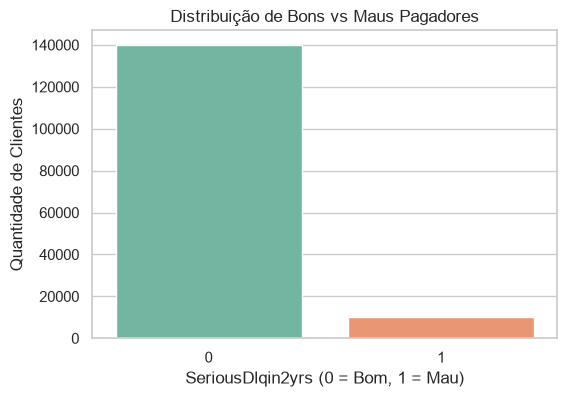

In [17]:
## Distribuição da Target

# 1. Calculando a contagem e porcentagem da variável alvo
alvo_counts = df_limpo['SeriousDlqin2yrs'].value_counts()
alvo_perc = df_limpo['SeriousDlqin2yrs'].value_counts(normalize=True) * 100

df_alvo_analise = pd.DataFrame({
    'Quantidade': alvo_counts,
    'Porcentagem (%)': alvo_perc.round(2)
})

print("Distribuição da Variável Alvo (SeriousDlqin2yrs):")
display(df_alvo_analise)

# 2. Gráfico de barras para visualizar o desbalanceamento
plt.figure(figsize=(6, 4))
sns.countplot(
    x='SeriousDlqin2yrs', 
    data=df_limpo, 
    hue='SeriousDlqin2yrs',
    palette='Set2',
    legend=False)
plt.title('Distribuição de Bons vs Maus Pagadores')
plt.xlabel('SeriousDlqin2yrs (0 = Bom, 1 = Mau)')
plt.ylabel('Quantidade de Clientes')
plt.show()

#### Conclusão Análise da Variável Alvo:
1. **Desbalanceamento Severo de Classes:** O gráfico e a tabela mostram que a base é altamente desbalanceada. A grande maioria dos clientes  é composta por bons pagadores (`0`), enquanto os maus pagadores (`1`) representam uma fração minoritária (cerca de 6,7%).
2. **Deafio para a Modelagem:** Isso significa que a **a acurácia não serve como métrica de sucesso** (um modelo que chuta sempre "0" teria mais de 93% de acurácia, mas quebraria o banco).

Nas próximas etapas de modelagem, teremos que utilizar métricas focadas na capacidade de separação e na classe minoritária, como a **ROC-AUC**, a **Curva Precision-Recall** e a **Estatística KS**.

### Etapa 5: Estratégia de Imputação de Valores Nulos

Para lidar com os nulos restantes (`MonthlyIncome`, `NumberOfDepents` e `NaN` gerados nas colunas de atraso), adotaremos as seguintes práticas:
1. **`MonthlyIncome` (Renda):** Como perde ~20% dos dados, além de imputar a mediana, criaremos uma **flag indicadora de ausência** (`MonthlyIncome_is_missing`), pois no mercado de crédito o fato do cliente não declarar renda já carrega um comportamento preditivo de risco. 
2. **`NumberOfDependents` e Colunas de Atraso:** Imputação pela mediana ou por 0 (representando ausência de dependentes ou histórico limpo de atrasos naqueles registros específicos).

In [18]:
## Aplicando a Imputação e Criando a Flag

# 1. Criando a Flag de ausência para a Renda Mensal antes de imputar
df_limpo['MonthlyIncome_is_missing'] = df_limpo['MonthlyIncome'].isnull().astype(int)

# 2. Imputando a Renda Mensal pela mediana (robusta contra outliers)
mediana_renda = df_limpo['MonthlyIncome'].median()
df_limpo['MonthlyIncome'] = df_limpo['MonthlyIncome'].fillna(mediana_renda)
print(f"Renda Mensal imputada pela mediana: {mediana_renda}")

# 3. Imputando NumberOfDependents pela mediana (ou moda, que geralmente é 0)
mediana_dependents = df_limpo['NumberOfDependents'].median()
df_limpo['NumberOfDependents'] = df_limpo['NumberOfDependents'].fillna(mediana_dependents)
print(f"Número de Dependentes imputados pela mediana: {mediana_dependents}")

# 4. Nas colunas de atraso onde transformamos 96/98 em NaN, preenchendo com 0 (sem registro dos que atrasam gravemente)
cols_atraso = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate',
    'NumberOfTime60-89DaysPastDueNotWorse'
]

for col in cols_atraso:
    df_limpo[col] = df_limpo[col].fillna(0)
    print(f"Valores nulos da coluna {col} preenchidos com 0.")

# 5. Verificação final de nulos no DataFrame limpo
print("\nVerificação final de valores nulos no dataset:")
print(df_limpo.isnull().sum()[df_limpo.isnull().sum() > 0])
print(f"\nDimensões finais do DataFrame limpo e tratado: {df_limpo.shape}")

Renda Mensal imputada pela mediana: 5400.0
Número de Dependentes imputados pela mediana: 0.0
Valores nulos da coluna NumberOfTime30-59DaysPastDueNotWorse preenchidos com 0.
Valores nulos da coluna NumberOfTimes90DaysLate preenchidos com 0.
Valores nulos da coluna NumberOfTime60-89DaysPastDueNotWorse preenchidos com 0.

Verificação final de valores nulos no dataset:
Series([], dtype: int64)

Dimensões finais do DataFrame limpo e tratado: (149999, 12)


#### Conclusão da Estratégia de Imputação e Higienização:

1. **Preservação de Informação Comportamental:** A criação da flag `MonthlyIncome_is_missing` assegura que o modelo capture o sinal preditivo implícito no fato de o cliente omitir ou não possuir renda formal declarada.
2. **Integridade Estrutural Assegurada:** Com a imputação robusta baseada em medianas para variáveis contínuas e o preenchimento lógico para o histórico de atrasos, eliminamos 100% dos valores ausentes sem descartar registros valiosos da base de treino.
3. **Base Pronta para Modelagem:** O dataset encontra-se íntegro, limpo e com dimensões estáveis `(149999, 12)`, apto para avançar para a fase de salvamento no banco SQLite ou para a exploração avançada de correlações e correções de multicolinearidade.

In [19]:
# Salvando o DataFrame limpo e tratado no banco SQLite para consumo do Notebook 03
caminho_db = '../data/credit_scoring.db'
conexao = sqlite3.connect(caminho_db)

df_limpo.to_sql('credito_tratado', conexao, if_exists='replace', index=False)
conexao.close()

print("Base tratada salva som sucesso na tabaela 'credito_tratado' do SQLite!")

Base tratada salva som sucesso na tabaela 'credito_tratado' do SQLite!
